# 02 · Data engineering (cleaning)

Input `data/comments_raw.csv` (9,561 rows) → output `data/comments_clean.csv`.

Each step logs how many rows it removes, and removed rows are kept in `data/comments_removed.csv` with the reason, so every decision can be checked. The ~6,000 row target is **not** forced: the rules are set from what the data looks like, and the final count is whatever they leave.

| # | Step | Rule |
|---|---|---|
| 1 | Empty | no text left (`text_body`, i.e. after removing whitespace, invisible characters and the leading reply `@handle` matched in notebook 01) |
| 2 | Creator's own comments | the channel commenting on its own video (pinned prompts, "subscribe" notes). These aren't audience opinion |
| 3 | Non-English | `langdetect` on comments with at least 30 letters (after removing handles, links, emoji and numbers) **and** a check that few common English words appear |
| 4 | Duplicates | normalized text; drop repeats by the same commenter, and copies of long text (25+ characters) by anyone. Short reactions from different people ("roll tide") are kept |
| 5 | Outdated | posted more than 72 hours after the video went up, **except** post-announcement comments on pre-announcement videos, which the event study needs |

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import emoji
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from langdetect import DetectorFactory, detect_langs

pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_raw.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["parent_id"] = df["parent_id"].replace("", np.nan)
raw_n = len(df)
df.shape

(9561, 25)

In [3]:
# Tunable settings (each is explained in its step below)
MIN_LETTERS_FOR_LANGDETECT = 30
MAX_EN_PROB = 0.10          # langdetect's probability of English must be below this to flag a comment
MAX_FUNCTION_WORD_SHARE = 0.15
MIN_LEN_CROSS_AUTHOR_DUP = 25
OUTDATED_HOURS = 72

cleaning_log, removed = [], []

def apply_step(df, drop_mask, step, rule):
    """Remove rows where drop_mask is True, log the counts, keep the removed rows."""
    drop_mask = drop_mask.reindex(df.index, fill_value=False)
    gone = df[drop_mask].assign(removed_step=step)
    removed.append(gone)
    cleaning_log.append({"step": step, "rule": rule, "before": len(df),
                         "removed": int(drop_mask.sum()), "after": int((~drop_mask).sum())})
    return df[~drop_mask].copy()

### Text helpers

* `text_body` (from notebook 01) is the comment without the leading reply `@handle` that YouTube adds when someone replies to a reply.
* `normalize` is used for duplicate checks: lowercase, no links, no emoji, no punctuation, single spaces.
* `language_text` keeps only the words, for language detection.

In [4]:
INVISIBLE = r"[\u200b\u200c\u200d\u2060\ufeff]"
HANDLE = r"@[\w.\-]+"

def normalize(s):
    s = re.sub(INVISIBLE, "", s).lower()
    s = re.sub(r"https?://\S+", " ", s)
    s = emoji.replace_emoji(s, " ")
    s = re.sub(r"[^\w\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

def language_text(s):
    s = re.sub(INVISIBLE, "", s)
    s = re.sub(HANDLE, " ", s)
    s = re.sub(r"https?://\S+", " ", s)
    s = emoji.replace_emoji(s, " ")
    s = re.sub(r"[\W\d_]+", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["text_norm"] = df["text_body"].apply(normalize)
df[["text", "text_body", "text_norm"]].sample(5, random_state=3)

,text,text_body,text_norm
3510,No 5 loss team (and very few 4 loss teams) will be ranked in the top 24??? Do you ever think before you ty...,No 5 loss team (and very few 4 loss teams) will be ranked in the top 24??? Do you ever think before you ty...,no 5 loss team and very few 4 loss teams will be ranked in the top 24 do you ever think before you type or...
2521,FIX THE THUMBNAIL.,FIX THE THUMBNAIL.,fix the thumbnail
7759,"I love that that the committee that decides the SEC is the greatest conference ever, despite evidence to c...","I love that that the committee that decides the SEC is the greatest conference ever, despite evidence to c...",i love that that the committee that decides the sec is the greatest conference ever despite evidence to co...
5457,@FIGHTON-ALLDAYone I’m not an Ohio state fan. Two yall won against a backup freshman quarterback in his fi...,one I’m not an Ohio state fan. Two yall won against a backup freshman quarterback in his first start. Thir...,one i m not an ohio state fan two yall won against a backup freshman quarterback in his first start third ...
8484,@antjohnson5464 that’s what they said last year too,that’s what they said last year too,that s what they said last year too


## 1. Empty comments

YouTube won't accept a fully blank comment, so this would only catch replies that are just an `@handle` or invisible characters. Emoji-only comments are **not** empty: they're kept for the emoji analysis.

In [5]:
is_empty = df["text_body"].str.strip() == ""
print("empty:", is_empty.sum())
display(df.loc[is_empty, ["video_id", "is_reply", "text"]])
df = apply_step(df, is_empty, "1_empty", "no text after removing whitespace, invisible characters, leading @handle")

empty: 0


,video_id,is_reply,text


## 2. Creator's own comments

In [6]:
print(df.loc[df["is_creator"], ["creator", "text"]].to_string(max_colwidth=90))
df = apply_step(df, df["is_creator"], "2_creator", "channel commenting on its own video")

         creator                                                                                       text
210         pate                 Keep the show rolling - SUBSCRIBE to the channel and LIKE the video!  - JP
1297  crain_cone                                    Who do you have winning in Death Valley - Texas or LSU?
2444  crain_cone  Does Missouri have a chance at another upset between the hedges, or will Georgia domin...
2496        pate                Keep the show rolling - SUBSCRIBE to the channel and LIKE the video!   - JP
2636  crain_cone  What's your biggest takeaway from these initial rankings for the College Football Play...
3147        pate                 Keep the show rolling - SUBSCRIBE to the channel and LIKE the video!  - JP
3542  crain_cone      What's your honest opinions about expanding the College Football Playoff to 24 teams?
4006  crain_cone                Did the committee do better or worse in the second edition of the rankings?
4029  crain_cone            

## 3. Non-English comments

Plain `langdetect` is unreliable on short, slangy sports comments. In testing it labelled "LSU over Utah is bonkers" Dutch and "Indiana doesn't play anyone😂" Tagalog. So:

1. Run it only on comments with at least 30 letters once handles, links, emoji and numbers are removed. Short comments like "W", "fraud 💀" or "Roll Tide" are kept unchecked.
2. Flag a comment only if langdetect's probability for English is below 10% **and** under 15% of its words are common English function words (the, is, and, you…). An English comment in all caps or full of team names can fool langdetect, but it still contains these words.
3. Read every flagged comment by hand. Any that are English go in `REVIEWED_ENGLISH` and are kept.

**Finding:** this corpus has essentially no non-English comments. Every comment langdetect flags turns out to be English slang, all caps, or a list of team names. The step stays in the pipeline (the assignment requires it), and the report shows that langdetect over-flags short sports comments.

In [7]:
FUNCTION_WORDS = set("""a an the and or but if so is are was were be been am i you he she it we they me him her us them my your his
its our their this that these those to of in on at for with by from up down out over not no do does did have has had will would
can could should just like what who why how when where there here all any some get got gonna im dont didnt cant wont thats""".split())

def english_prob(text):
    DetectorFactory.seed = 0          # langdetect is random; a fixed seed makes results repeat
    try:
        return {l.lang: l.prob for l in detect_langs(text)}
    except Exception:
        return {}

def function_word_share(text):
    words = text.lower().split()
    return sum(w in FUNCTION_WORDS for w in words) / len(words) if words else 0.0

lang = df["text_body"].apply(language_text)
n_letters = lang.str.count(r"[^\W\d_]")
eligible = n_letters >= MIN_LETTERS_FOR_LANGDETECT
probs = lang[eligible].apply(english_prob)

lang_check = pd.DataFrame({
    "top_lang": probs.apply(lambda d: max(d, key=d.get) if d else "unknown"),
    "p_en": probs.apply(lambda d: d.get("en", 0.0)),
    "fw_share": lang[eligible].apply(function_word_share),
    "text": df.loc[eligible, "text"],
})
print(f"checked {eligible.sum():,} of {len(df):,} comments (the rest are under {MIN_LETTERS_FOR_LANGDETECT} letters)")
print("langdetect top language:")
print(lang_check["top_lang"].value_counts().head(10).to_string())

checked 7,743 of 9,541 comments (the rest are under 30 letters)
langdetect top language:
top_lang
en    7707
id       8
af       6
nl       5
de       4
tl       2
da       2
cy       2
et       2
vi       1


In [8]:
# Comments the rule flags that were read by hand and are English (documented manual review)
REVIEWED_ENGLISH = {
    "Ugz0SkCtRVKuhm38W2p4AaABAg",                          # "CAMP PENDLETON, CA. HAPPY BIRTHDAY MARINES"
    "UgzNMNQZNmaqKcAey1d4AaABAg.Ad39zb6Mv5aAd6FQv6Exwa",   # "OSU dogwalked Oregon. Stop talking ish."
}
lang_check["comment_id"] = df.loc[lang_check.index, "comment_id"]

ld_flag = lang_check["p_en"] < MAX_EN_PROB
rule_flag = ld_flag & (lang_check["fw_share"] < MAX_FUNCTION_WORD_SHARE)
non_english = rule_flag & ~lang_check["comment_id"].isin(REVIEWED_ENGLISH)

print(f"langdetect alone would flag {ld_flag.sum()} comments; with the English-words check: {rule_flag.sum()}; "
      f"after manual review: {non_english.sum()}")
print("\nFlagged by langdetect but KEPT (enough English function words):")
display(lang_check[ld_flag & ~non_english].sort_values("fw_share").head(20))
print("Flagged by the rule, then read by hand:")
display(lang_check[rule_flag].assign(reviewed_english=lambda x: x["comment_id"].isin(REVIEWED_ENGLISH)))

langdetect alone would flag 14 comments; with the English-words check: 2; after manual review: 0

Flagged by langdetect but KEPT (enough English function words):


,top_lang,p_en,fw_share,text,comment_id
130,vi,0.0,0.000000,"CAMP PENDLETON, CA. HAPPY BIRTHDAY MARINES🦅🌎⚓️",Ugz0SkCtRVKuhm38W2p4AaABAg
9065,af,0.0,0.000000,OSU dogwalked Oregon. Stop talking ish.,UgzNMNQZNmaqKcAey1d4AaABAg.Ad39zb6Mv5aAd6FQv6Exwa
7159,da,0.0,0.272727,"​@Necile2 ... somebody doesn't like rules and it shows. tisk, tisk, tisk",Ugz6uc0FwtFG9OZrhoR4AaABAg.AcyyEe1icQ6AczMWKIV_Ib
6209,id,0.0,0.272727,"I hate Bama, but ND, Miami vs Bama??😂. Bama will win",Ugzmf0Uwbs0lCijrZvJ4AaABAg
6576,de,0.0,0.285714,"USC HAS SOME FREAKS: WAFFLE, ABASIRI, STEWART",UgzD2fjnUhFkXJ1SqdJ4AaABAg.Acy_XfFocvYAcymswjky3r
4001,et,0.0,0.285714,@luvvv4ymsssskinda like Ohio state and Oregon too? 😮,UgzvIh5n_Q28JedAytB4AaABAg.Ad-KNLilbx9Ad-R4uX0ATL
7218,et,0.0,0.300000,@vargo006just like Miami last year lmao. You sound mad pissed 😂,Ugz6uc0FwtFG9OZrhoR4AaABAg.AcyyEe1icQ6Ad-a0YnG-kW
6739,id,0.0,0.333333,Bama behind Indiana is insane.\nBama has 3-4 ranked wins\nIndiana has 0. Miami has 1. ND has 1.,UgxHajZxkB3DVE2cDap4AaABAg
7348,nl,0.0,0.333333,Not gonna happen against texas defense,Ugyjl0kfWb50C42-TDx4AaABAg
1234,cy,0.0,0.375000,"​@BigMonty686lol, fsu didnt get robbed. Neither did miami.",UgwmxHBGpiiZpRc65xJ4AaABAg.AcyTbCp2u68Acz8iPR1wY0


Flagged by the rule, then read by hand:


,top_lang,p_en,fw_share,text,comment_id,reviewed_english
130,vi,0.0,0.0,"CAMP PENDLETON, CA. HAPPY BIRTHDAY MARINES🦅🌎⚓️",Ugz0SkCtRVKuhm38W2p4AaABAg,True
9065,af,0.0,0.0,OSU dogwalked Oregon. Stop talking ish.,UgzNMNQZNmaqKcAey1d4AaABAg.Ad39zb6Mv5aAd6FQv6Exwa,True


In [9]:
df = apply_step(df, non_english.reindex(df.index, fill_value=False), "3_non_english",
                f"langdetect P(en) < {MAX_EN_PROB} and English function words < {MAX_FUNCTION_WORD_SHARE:.0%}, on comments with 30+ letters")

## 4. Duplicates

Text is normalized first (lowercase, no punctuation, emoji, links or leading handle), so "Roll Tide!!" and "roll tide" match. Two kinds of duplicate are removed, keeping the earliest copy:

* **Same commenter, same text**: reposts, double submissions, someone pasting the same reply under several comments.
* **Long text (25+ characters) copied by anyone**: copy-paste spam and bots.

Short reactions repeated by *different* people ("roll tide", "go dawgs", "lol", "facts") are independent opinions, not copies, so they stay. Comments with no text after normalizing (emoji-only) aren't compared.

In [10]:
df = df.sort_values("published_utc")
has_text = df["text_norm"] != ""

same_author = has_text & df.duplicated(["author_channel_id", "text_norm"], keep="first")
long_copy = has_text & (df["text_norm"].str.len() >= MIN_LEN_CROSS_AUTHOR_DUP) & df.duplicated("text_norm", keep="first")
is_dup = same_author | long_copy

print(f"same commenter repeats: {same_author.sum()}   long copies by anyone: {long_copy.sum()}   "
      f"total removed: {is_dup.sum()}")
kept_short = df[has_text & ~is_dup & df.duplicated("text_norm", keep=False)]
print(f"short reactions repeated by different people (kept): {len(kept_short)} rows")
print(kept_short["text_norm"].value_counts().head(12).to_string())

same commenter repeats: 42   long copies by anyone: 23   total removed: 43
short reactions repeated by different people (kept): 151 rows
text_norm
roll tide    9
exactly      9
same         7
go dawgs     6
texas        6
lol          5
facts        5
fight on     4
drugs        4
and          3
gbo          3
terrible     3


In [11]:
print("Most repeated texts among the removed duplicates:")
display(df[is_dup]["text_norm"].str[:90].value_counts().head(10))
df = apply_step(df, is_dup, "4_duplicates",
                "same commenter + same normalized text, or normalized text 25+ characters repeated by anyone (earliest kept)")

Most repeated texts among the removed duplicates:


text_norm
usc 30 osu 18                                                                                 5
umm no                                                                                        4
you re stuck in the past nil and transfer portal changed the game several teams in several    2
congrats                                                                                      2
lsu and iowa are not getting in over oregon if they win out and that looks pretty likely m    2
please god can you bring up the volume my ears are getting blasted every time a commercial    2
michigan                                                                                      2
nope sec is the class of college football                                                     2
genuinely the reason they are top 5 in the rankings is bc cfp is acknowledging the no call    1
fsu unc wake forest miami would all wax your favorite team                                    1
Name: count, dtype: int64

## 5. Outdated comments

All comments were collected on Nov 14, within six days of most uploads. No comment came more than 5.75 days after its video, so a fixed "older than N days" rule would remove nothing. Instead, "outdated" is defined relative to each video and to the announcement:

* A comment is **outdated** if it was posted more than **72 hours** after its video went up. By then the discussion has moved on to newer videos (90% of comments arrive within about 26 hours). The cutoff also gives every video a similar window: older videos would otherwise have extra days of late comments.
* **Exception:** comments on *pre-announcement* videos that were posted *after* the announcement are always kept. They're the treatment group for the within-video event study.

posted > 72h after upload: 79  (protected post-announcement comments on pre-announcement videos: 37)
removed as outdated: 42


removed
creator    video_title                                                                                 
crain_cone 24-TEAM College Football Playoff CONFIRMED | Is This GOOD Or BAD For CFB?                 15
           FIRST College Football Playoff Rankings Reveal LIVE REACTION | WORST RANKINGS EVER?        3
pate       CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show            19
           Why The 24-Team CFP Is A Massive Mistake - Josh Pate's College Football Show               5

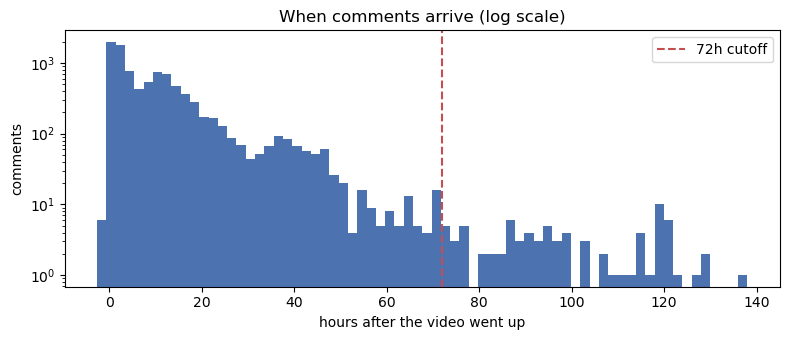

In [12]:
hours = df["hours_since_upload"]
pre_video = df["video_published_utc"] < config.ANNOUNCE_UTC
protected = pre_video & df["after_announce"]
outdated = (hours > OUTDATED_HOURS) & ~protected

print(f"posted > {OUTDATED_HOURS}h after upload: {(hours > OUTDATED_HOURS).sum()}  "
      f"(protected post-announcement comments on pre-announcement videos: {((hours > OUTDATED_HOURS) & protected).sum()})")
print(f"removed as outdated: {outdated.sum()}")
display(df[outdated].groupby(["creator", "video_title"]).size().rename("removed").to_frame())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(hours.clip(upper=140), bins=70, color="#4C72B0")
ax.axvline(OUTDATED_HOURS, color="#C44E52", ls="--", label=f"{OUTDATED_HOURS}h cutoff")
ax.set(xlabel="hours after the video went up", ylabel="comments", yscale="log",
       title="When comments arrive (log scale)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "02_comment_age_hist.png", dpi=150)

In [13]:
df = apply_step(df, outdated, "5_outdated",
                f"posted > {OUTDATED_HOURS}h after upload, except post-announcement comments on pre-announcement videos")

## Cleaning log

In [14]:
log = pd.DataFrame(cleaning_log)
log["removed_%"] = (log["removed"] / raw_n * 100).round(2)
display(log)
print(f"raw {raw_n:,} -> clean {len(df):,}  ({len(df) / raw_n:.1%} kept)")

,step,rule,before,removed,after,removed_%
0,1_empty,"no text after removing whitespace, invisible characters, leading @handle",9561,0,9561,0.00
1,2_creator,channel commenting on its own video,9561,20,9541,0.21
2,3_non_english,"langdetect P(en) < 0.1 and English function words < 15%, on comments with 30+ letters",9541,0,9541,0.00
3,4_duplicates,"same commenter + same normalized text, or normalized text 25+ characters repeated by anyone (earliest kept)",9541,43,9498,0.45
4,5_outdated,"posted > 72h after upload, except post-announcement comments on pre-announcement videos",9498,42,9456,0.44


raw 9,561 -> clean 9,456  (98.9% kept)


In [15]:
by_video = (pd.concat(removed).groupby(["video_id", "removed_step"]).size().unstack(fill_value=0)
            .reindex(df["video_id"].unique(), fill_value=0))
summary = (df.groupby(["role", "creator", "video_id", "video_title"]).size().rename("clean").reset_index()
           .set_index("video_id").join(by_video))
summary

,role,creator,video_title,clean,2_creator,4_duplicates,5_outdated
video_id,,,,,,,
VC4NmThPfkc,primary,crain_cone,FIRST College Football Playoff Rankings Reveal LIVE REACTION | WORST RANKINGS EVER?,503,1,4,3
cFgBGGl2pQg,primary,crain_cone,24-TEAM College Football Playoff CONFIRMED | Is This GOOD Or BAD For CFB?,448,1,0,15
iGYPNyDioi8,primary,crain_cone,College Football Playoff Rankings Reveal LIVE REACTION,275,4,1,0
rAqrsZlhTkc,primary,crain_cone,College Football Week 11 AP Poll Top-25 REACTION,221,1,3,0
sISy77HQw2o,primary,crain_cone,"College Football Week 11 PREDICTIONS with Brooks Austin | Texas-LSU, USC-Indiana, Michigan-Oregon",152,2,3,0
CRR3qVcpRDY,primary,pate,AP Poll Week 11 Reaction...MOST Overrated & Underrated Teams - Josh Pate's College Football Show,1085,1,1,0
_LpZ2hHLOCQ,primary,pate,Why The 24-Team CFP Is A Massive Mistake - Josh Pate's College Football Show,389,1,0,5
karqas42RcE,primary,pate,CFP Rankings Reaction...WHAT Are We Doing? - Josh Pate's College Football Show,1771,2,15,14
njO_8Yg7HKk,primary,pate,Week 11 Upset Alerts | Commissioner’s Poll Top 25 | CFP Chaos Scenarios | How Many Title Contenders?,383,1,1,0


In [16]:
after = df[df["video_published_utc"] < config.ANNOUNCE_UTC]
print("Pre-announcement videos after cleaning, comments split at the announcement:")
after.groupby("creator")["after_announce"].value_counts().unstack().rename(columns={False: "before", True: "after"})

Pre-announcement videos after cleaning, comments split at the announcement:


after_announce,before,after
creator,,
crain_cone,929,229
pate,3611,984


## Save

In [17]:
df = df.sort_values(["video_id", "published_utc"])
df.to_csv(config.DATA_DIR / "comments_clean.csv", index=False)
pd.concat(removed).to_csv(config.DATA_DIR / "comments_removed.csv", index=False)
log.to_csv(config.DATA_DIR / "cleaning_log.csv", index=False)
print(f"saved comments_clean.csv ({len(df):,} rows), comments_removed.csv, cleaning_log.csv")

saved comments_clean.csv (9,456 rows), comments_removed.csv, cleaning_log.csv
